# 讀取 Köppen-Geiger 氣候分類 GeoTIFF

```
讀取 Beck et al. (2023) Köppen-Geiger 氣候分類 GeoTIFF 的範例。
執行環境：conda 的 Geography 環境（內含 rasterio）
    ~/opt/anaconda3/envs/Geography/bin/python read_koppen.py

資料格式（四個檔案都一樣，只差解析度）：
    單波段 uint8、EPSG:4326 經緯度、範圍 -180~180 / -90~90
    像素值 0 = 海洋/無資料 (nodata)，1~30 = 氣候類別（見 legend.txt）
    檔內已附調色盤（顏色與論文相同）
```

In [1]:
from pathlib import Path
import re
import numpy as np
import rasterio
from rasterio.windows import from_bounds

# notebook 放在 Code/ 底下，資料與圖在上一層
ROOT = Path.cwd().parent if Path.cwd().name == "Code" else Path.cwd()
BASE = ROOT / "Data"
FIG = ROOT / "Figure"
FIG.mkdir(exist_ok=True)
for _d in ("koppen_figures", "Africa_curves"):   # Köppen 圖 / 非洲曲線圖分開放
    (FIG / _d).mkdir(exist_ok=True)
PERIOD = "1991_2020"
# 解析度：0p00833333 (~1 km, 43200x21600)、0p1、0p5、1p0（度）
TIF = BASE / PERIOD / "koppen_geiger_0p1.tif"


def load_legend(path=BASE / "legend.txt"):
    """回傳 {代碼: (簡稱, 說明, (R,G,B))}"""
    legend = {}
    pat = re.compile(r"^\s*(\d+):\s+(\S+)\s+(.+?)\s+\[(\d+) (\d+) (\d+)\]")
    for line in path.read_text(encoding="utf-8").splitlines():
        m = pat.match(line)
        if m:
            code, abbr, desc, r, g, b = m.groups()
            legend[int(code)] = (abbr, desc, (int(r), int(g), int(b)))
    return legend


LEGEND = load_legend()

## 1) 讀整張圖（0.1° 只有 3600x1800，可直接讀）

In [2]:
with rasterio.open(TIF) as ds:
    print(ds.width, ds.height, ds.crs, ds.res, "nodata =", ds.nodata)
    data = ds.read(1)               # numpy uint8 陣列，[列=緯度由北往南, 欄=經度由西往東]

3600 1800 EPSG:4326 (0.1, 0.1) nodata = 0.0


## 2) 查詢單點（經度, 緯度）

In [3]:
points = {"台北": (121.56, 25.04), "阿里山": (120.80, 23.51), "開羅": (31.24, 30.04)}
with rasterio.open(TIF) as ds:
    for name, (lon, lat) in points.items():
        code = int(next(ds.sample([(lon, lat)]))[0])
        abbr, desc, _ = LEGEND.get(code, ("-", "海洋/無資料", None))
        print(f"{name}: {code} {abbr} {desc}")

台北: 14 Cfa Temperate, no dry season, hot summer
阿里山: 12 Cwb Temperate, dry winter, warm summer
開羅: 4 BWh Arid, desert, hot


## 3) 只讀一塊區域（例如台灣）——1 km 大檔建議都用視窗讀取，不要整張讀進記憶體

In [4]:
TW = (119.3, 21.8, 122.1, 25.4)     # (west, south, east, north)
with rasterio.open(BASE / PERIOD / "koppen_geiger_0p00833333.tif") as ds:
    win = from_bounds(*TW, transform=ds.transform)
    tw = ds.read(1, window=win)
    tw_transform = ds.window_transform(win)
    cmap = ds.colormap(1)           # 內建調色盤 {值: (R,G,B,A)}
print("台灣區塊大小:", tw.shape)

台灣區塊大小: (432, 336)


## 4) 各類別像素數與比例（排除 0）。注意：經緯度網格面積隨緯度變，
全球統計要用 cos(緯度) 加權，小區域（如台灣）直接算像素即可。

In [5]:
vals, counts = np.unique(tw[tw > 0], return_counts=True)
for v, c in sorted(zip(vals, counts), key=lambda x: -x[1]):
    print(f"{LEGEND[v][0]:>4} {LEGEND[v][1]:<38} {c / counts.sum():6.1%}")

 Cfa Temperate, no dry season, hot summer    31.3%
 Cwa Temperate, dry winter, hot summer       31.2%
 Cfb Temperate, no dry season, warm summer   19.5%
  Am Tropical, monsoon                        7.8%
 Cwb Temperate, dry winter, warm summer       6.0%
  Aw Tropical, savannah                       2.9%
  Af Tropical, rainforest                     0.8%
 Cfc Temperate, no dry season, cold summer    0.4%
  ET Polar, tundra                            0.1%
 Dfc Cold, no dry season, cold summer         0.0%
 Cwc Temperate, dry winter, cold summer       0.0%


## 5) 畫圖（用論文配色）

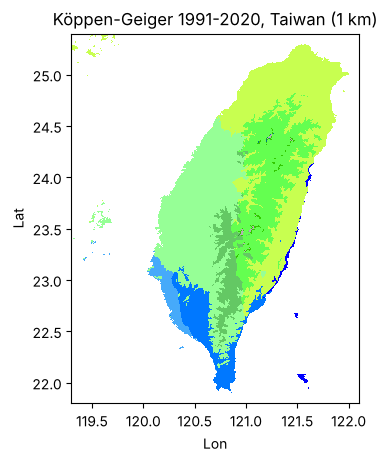

In [6]:
try:
    import matplotlib.pyplot as plt
    from matplotlib.colors import ListedColormap, BoundaryNorm
    colors = [(1, 1, 1)] + [tuple(c / 255 for c in LEGEND[i][2]) for i in range(1, 31)]
    cm = ListedColormap(colors)
    norm = BoundaryNorm(np.arange(-0.5, 31), cm.N)
    w, s, e, n = TW
    plt.imshow(tw, cmap=cm, norm=norm, extent=(w, e, s, n), interpolation="nearest")
    plt.title("Köppen-Geiger 1991-2020, Taiwan (1 km)")
    plt.xlabel("Lon"); plt.ylabel("Lat")
    plt.savefig(FIG / "koppen_figures" / "koppen_taiwan.png", dpi=150, bbox_inches="tight")
    plt.show()
except ImportError:
    pass

## 6) 全球圖（0.5°）
0.5° 檔只有 720×360 像素（約 0.26 MB 記憶體），整張讀進來完全沒問題。

(360, 720) 0.26 MB


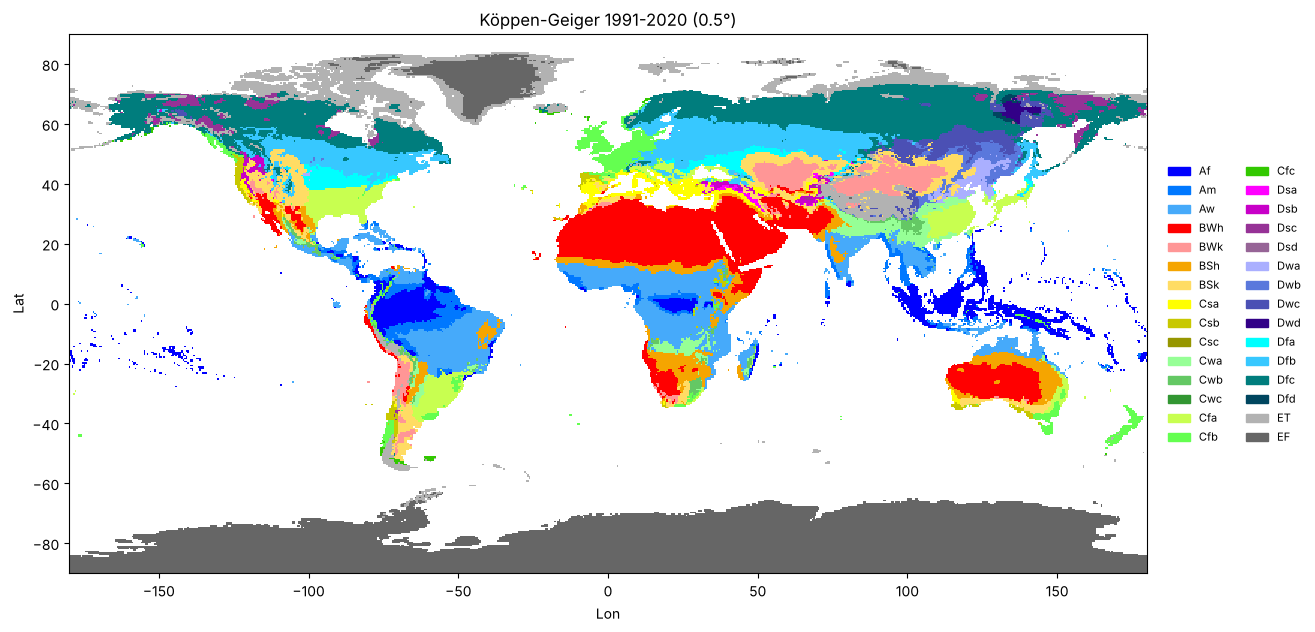

In [7]:
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

with rasterio.open(BASE / PERIOD / "koppen_geiger_0p5.tif") as ds:
    g = ds.read(1)
    b = ds.bounds
print(g.shape, f"{g.nbytes/1e6:.2f} MB")

colors = [(1, 1, 1)] + [tuple(c / 255 for c in LEGEND[i][2]) for i in range(1, 31)]
cm = ListedColormap(colors)
norm = BoundaryNorm(np.arange(-0.5, 31), cm.N)

fig, ax = plt.subplots(figsize=(14, 7))
ax.imshow(g, cmap=cm, norm=norm, extent=(b.left, b.right, b.bottom, b.top), interpolation="nearest")
ax.set_title("Köppen-Geiger 1991-2020 (0.5°)")
ax.set_xlabel("Lon"); ax.set_ylabel("Lat")
handles = [Patch(color=colors[i], label=LEGEND[i][0]) for i in range(1, 31)]
ax.legend(handles=handles, loc="center left", bbox_to_anchor=(1.01, 0.5), ncol=2, fontsize=8, frameon=False)
plt.savefig(FIG / "koppen_figures" / "koppen_global_0p5.png", dpi=150, bbox_inches="tight")
plt.show()

## 7) 沙漠範圍：BWh (4) + BWk (5)
直接用代碼篩選 `(g == 4) | (g == 5)`；其他陸地畫淺灰當底圖。

沙漠占陸地面積：17.1%  (BWh 13.9%, BWk 3.2%)


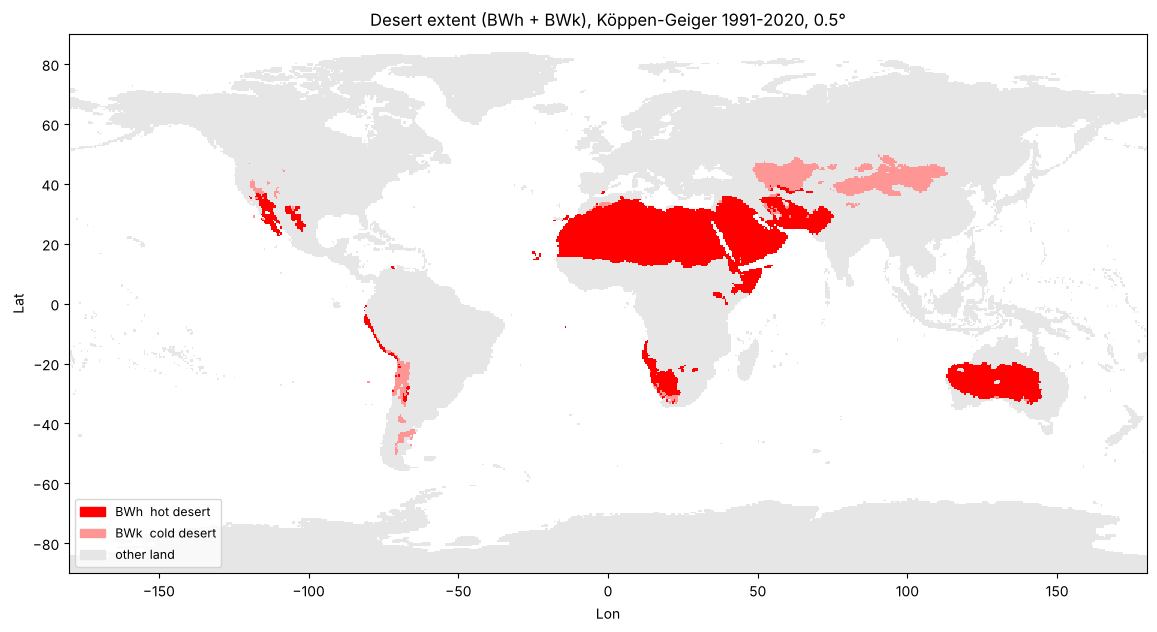

In [8]:
desert = (g == 4) | (g == 5)

# 0 = 海洋, 1 = 其他陸地, 2 = BWh, 3 = BWk
show = np.where(g > 0, 1, 0)
show[g == 4] = 2
show[g == 5] = 3
dcm = ListedColormap(["white", "#e6e6e6", tuple(np.array(LEGEND[4][2]) / 255), tuple(np.array(LEGEND[5][2]) / 255)])

# 面積比例：經緯度網格面積 ∝ cos(緯度)
lat = np.linspace(b.top, b.bottom, g.shape[0], endpoint=False) - 0.25   # 0.5° 格子中心
w = np.cos(np.deg2rad(lat))[:, None] * np.ones_like(g, dtype=float)
land = g > 0
print(f"沙漠占陸地面積：{w[desert].sum() / w[land].sum():.1%}  "
      f"(BWh {w[g == 4].sum() / w[land].sum():.1%}, BWk {w[g == 5].sum() / w[land].sum():.1%})")

fig, ax = plt.subplots(figsize=(14, 7))
ax.imshow(show, cmap=dcm, vmin=-0.5, vmax=3.5, extent=(b.left, b.right, b.bottom, b.top), interpolation="nearest")
ax.set_title("Desert extent (BWh + BWk), Köppen-Geiger 1991-2020, 0.5°")
ax.set_xlabel("Lon"); ax.set_ylabel("Lat")
ax.legend(handles=[Patch(color=dcm.colors[2], label="BWh  hot desert"),
                   Patch(color=dcm.colors[3], label="BWk  cold desert"),
                   Patch(color=dcm.colors[1], label="other land")],
          loc="lower left", fontsize=9)
plt.savefig(FIG / "koppen_figures" / "desert_BWh_BWk_0p5.png", dpi=150, bbox_inches="tight")
plt.show()